# Hydraulic System Condition Monitoring — Exploratory Data Analysis

**Business problem.** Unplanned hydraulic failures stop production lines. If we can detect *which* component is degrading (cooler, valve, pump, accumulator) from routine sensor data, maintenance shifts from reactive firefighting to planned, low-cost interventions.

**What this notebook does.** Inspects the UCI hydraulic test-rig dataset (2,205 sixty-second operating cycles, 17 sensors, per-cycle component health labels) to answer: *do the sensor signals actually separate the fault classes?*

**Dataset:** Helwig et al., "Condition monitoring of hydraulic systems", UCI Machine Learning Repository (2018). Independent portfolio project — public research data, not affiliated with any employer.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, "../src")
from data import load_profile, load_sensor, SENSORS, SENSOR_INFO, TARGETS, TARGET_LABELS

FIG = "../reports/figures"
os.makedirs(FIG, exist_ok=True)

profile = load_profile()
print("cycles:", len(profile))
profile.head()


cycles: 2205


,cooler,valve,pump,accumulator,stable
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


## 1. Target variables — how the four components degrade

Each cycle is labeled with the health state of four components. Class balance matters: a model can cheat on imbalanced targets, so we check first.


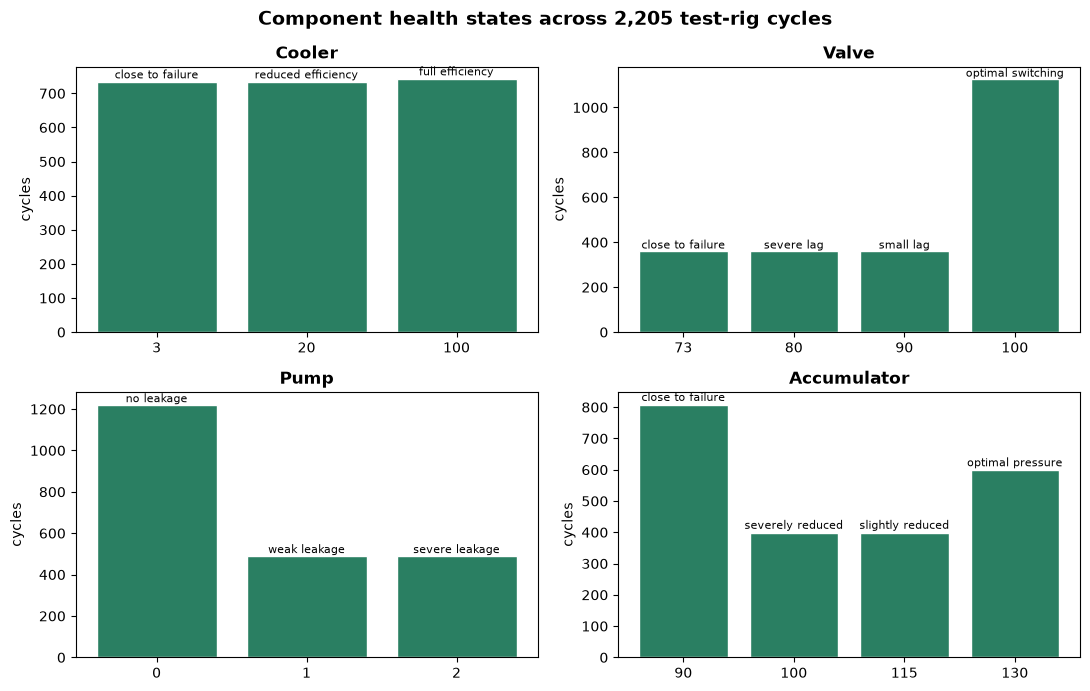

              count        mean        std   min   25%    50%    75%    max
cooler       2205.0   41.240816  42.383143   3.0   3.0   20.0  100.0  100.0
valve        2205.0   90.693878  10.681802  73.0  80.0  100.0  100.0  100.0
pump         2205.0    0.669388   0.817233   0.0   0.0    0.0    1.0    2.0
accumulator  2205.0  107.199546  16.435848  90.0  90.0  100.0  130.0  130.0


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, t in zip(axes.ravel(), TARGETS):
    counts = profile[t].value_counts().sort_index()
    labels = [f"{v}\n{TARGET_LABELS[t][v]}" for v in counts.index]
    ax.bar([str(v) for v in counts.index], counts.values, color="#2a7f62", edgecolor="white")
    ax.set_title(t.capitalize(), fontsize=12, fontweight="bold")
    ax.set_ylabel("cycles")
    for i, (v, c) in enumerate(zip(counts.index, counts.values)):
        ax.text(i, c + 12, TARGET_LABELS[t][v], ha="center", fontsize=8, rotation=0)
fig.suptitle("Component health states across 2,205 test-rig cycles", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/01_target_distributions.png", dpi=120)
plt.show()
print(profile[TARGETS].describe().T)


## 2. Sensor inventory

17 sensors at three sampling rates. High-rate pressure/power signals (100 Hz → 6,000 samples/cycle) carry the fast dynamics; 1 Hz temperature/vibration signals carry the slow thermal picture.


In [3]:
rows = []
for s in SENSORS:
    a = load_sensor(s)
    rate = {6000: "100 Hz", 600: "10 Hz", 60: "1 Hz"}[a.shape[1]]
    rows.append({"sensor": s, "description": SENSOR_INFO[s], "sampling": rate,
                 "shape": f"{a.shape[0]} x {a.shape[1]}"})
inv = pd.DataFrame(rows).set_index("sensor")
print(inv.to_string())
print("\nTotal raw values per cycle:",
      sum(load_sensor(s).shape[1] for s in SENSORS))


                         description sampling        shape
sensor                                                    
CE      Cooling efficiency, 1 Hz (%)     1 Hz    2205 x 60
CP          Cooling power, 1 Hz (kW)     1 Hz    2205 x 60
EPS1         Motor power, 100 Hz (W)   100 Hz  2205 x 6000
FS1       Volume flow, 10 Hz (l/min)    10 Hz   2205 x 600
FS2       Volume flow, 10 Hz (l/min)    10 Hz   2205 x 600
PS1           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
PS2           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
PS3           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
PS4           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
PS5           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
PS6           Pressure, 100 Hz (bar)   100 Hz  2205 x 6000
SE       Efficiency factor, 1 Hz (%)     1 Hz    2205 x 60
TS1            Temperature, 1 Hz (C)     1 Hz    2205 x 60
TS2            Temperature, 1 Hz (C)     1 Hz    2205 x 60
TS3            Temperature, 1 Hz (C)     1 Hz    2205 x 


Total raw values per cycle: 43680


## 3. Data quality: trust, but verify

Before any analysis: missing values, infinities, duplicate cycles, and whether the labels match the documented health states. Real industrial data is never this clean — checking is a habit, not a formality.

In [4]:
print("=== sensor files ===")
for s in SENSORS:
    a = load_sensor(s)
    print(f"{s:5s} shape={str(a.shape):16s} NaNs={np.isnan(a).sum():,}  infs={np.isinf(a).sum():,}")
print("\nprofile NaNs:", int(profile.isna().sum().sum()))
print("duplicate profile rows:", int(profile.duplicated().sum()),
      "(expected >0: the rig repeats conditions by design)")
ok = all(set(profile[t].unique()) == set(TARGET_LABELS[t].keys()) for t in TARGETS)
print("labels match documentation:", ok)

=== sensor files ===
CE    shape=(2205, 60)       NaNs=0  infs=0
CP    shape=(2205, 60)       NaNs=0  infs=0


EPS1  shape=(2205, 6000)     NaNs=0  infs=0


FS1   shape=(2205, 600)      NaNs=0  infs=0


FS2   shape=(2205, 600)      NaNs=0  infs=0


PS1   shape=(2205, 6000)     NaNs=0  infs=0


...

PS3   shape=(2205, 6000)     NaNs=0  infs=0


PS4   shape=(2205, 6000)     NaNs=0  infs=0


PS5   shape=(2205, 6000)     NaNs=0  infs=0


PS6   shape=(2205, 6000)     NaNs=0  infs=0
SE    shape=(2205, 60)       NaNs=0  infs=0
TS1   shape=(2205, 60)       NaNs=0  infs=0
TS2   shape=(2205, 60)       NaNs=0  infs=0
TS3   shape=(2205, 60)       NaNs=0  infs=0


TS4   shape=(2205, 60)       NaNs=0  infs=0
VS1   shape=(2205, 60)       NaNs=0  infs=0

profile NaNs: 0
duplicate profile rows: 2025 (expected >0: the rig repeats conditions by design)
labels match documentation: True


## 4. What one raw cycle looks like

Before aggregating anything, look at the raw material: six random 60-second cycles of oil temperature (TS3) and system pressure (PS1). Every feature we engineer later is a compression of curves like these.

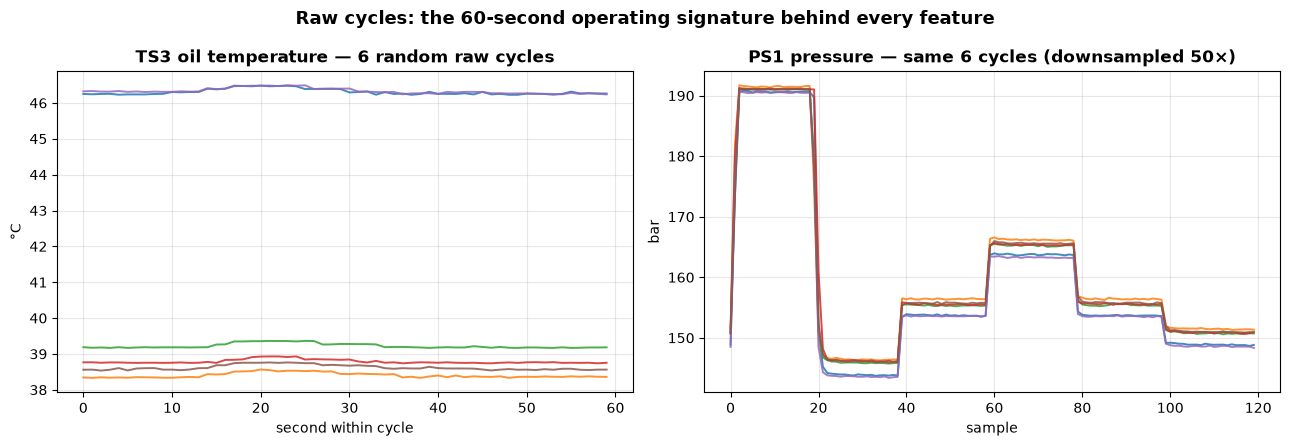

In [5]:
rng = np.random.default_rng(7)
idx = rng.choice(len(profile), 6, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ts3 = load_sensor("TS3")
for i in idx:
    axes[0].plot(ts3[i], lw=1.4, alpha=0.85)
axes[0].set_title("TS3 oil temperature — 6 random raw cycles", fontweight="bold")
axes[0].set_xlabel("second within cycle"); axes[0].set_ylabel("°C")
axes[0].grid(alpha=0.3)
ps1 = load_sensor("PS1")[:, ::50]
for i in idx:
    axes[1].plot(ps1[i], lw=1.4, alpha=0.85)
axes[1].set_title("PS1 pressure — same 6 cycles (downsampled 50×)", fontweight="bold")
axes[1].set_xlabel("sample"); axes[1].set_ylabel("bar")
axes[1].grid(alpha=0.3)
fig.suptitle("Raw cycles: the 60-second operating signature behind every feature",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/08_raw_cycles.png", dpi=120)
plt.show()

## 5. Sensor redundancy map

Per-cycle sensor means, correlated against each other. Strong blocks tell us which sensors watch the same physical loop (expected: the four temperature sensors move together) — useful context when we later ask *where to spend instrumentation budget*. Tree models tolerate this redundancy fine.

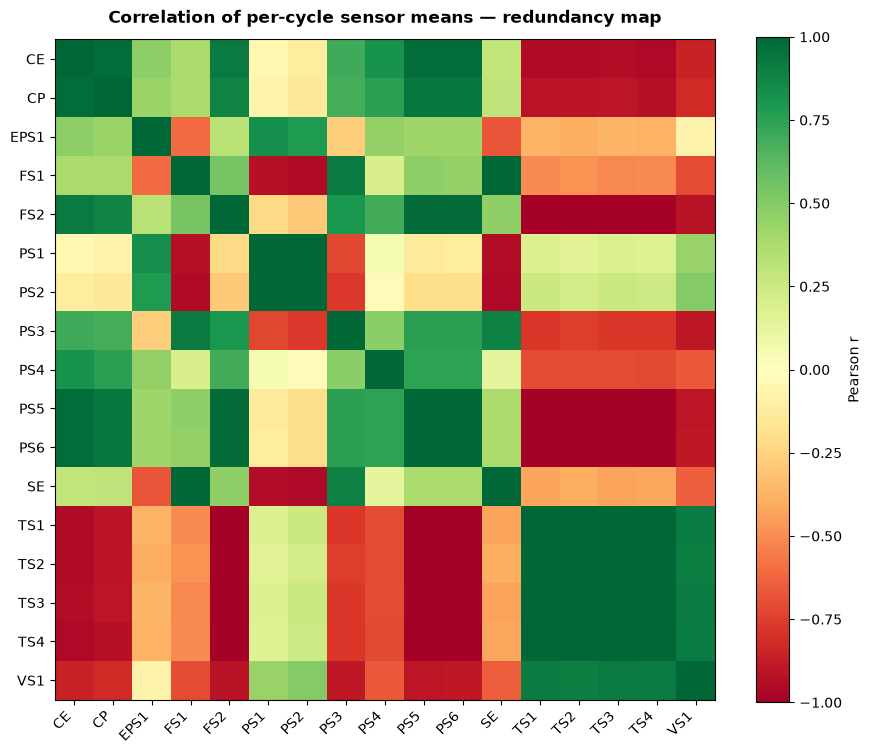

Strongest off-diagonal pairs:
PS5  PS6    0.999993
PS6  PS5    0.999993
TS1  TS3    0.999732
TS3  TS1    0.999732
TS1  TS2    0.999344
TS2  TS1    0.999344


In [6]:
means = pd.DataFrame({s: load_sensor(s).mean(axis=1) for s in SENSORS})
corr = means.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(SENSORS))); ax.set_yticks(range(len(SENSORS)))
ax.set_xticklabels(SENSORS, rotation=45, ha="right")
ax.set_yticklabels(SENSORS)
ax.set_title("Correlation of per-cycle sensor means — redundancy map",
            fontweight="bold", pad=12)
fig.colorbar(im, ax=ax, label="Pearson r")
fig.tight_layout()
fig.savefig(f"{FIG}/09_sensor_corr.png", dpi=120)
plt.show()
print("Strongest off-diagonal pairs:")
c = corr.where(~np.eye(len(corr), dtype=bool)).stack().sort_values(ascending=False)
print(c.head(6).to_string())

## 6. Do the signals separate the fault classes?

The key EDA question. If mean signal traces already diverge by health state, a classifier has something real to learn. Two physical hypotheses:
- **Cooler degradation → higher oil temperatures** (temperature sensors TS1–TS4 should separate)
- **Valve lag → altered pressure dynamics** (pressure sensors PS1–PS6 should separate)


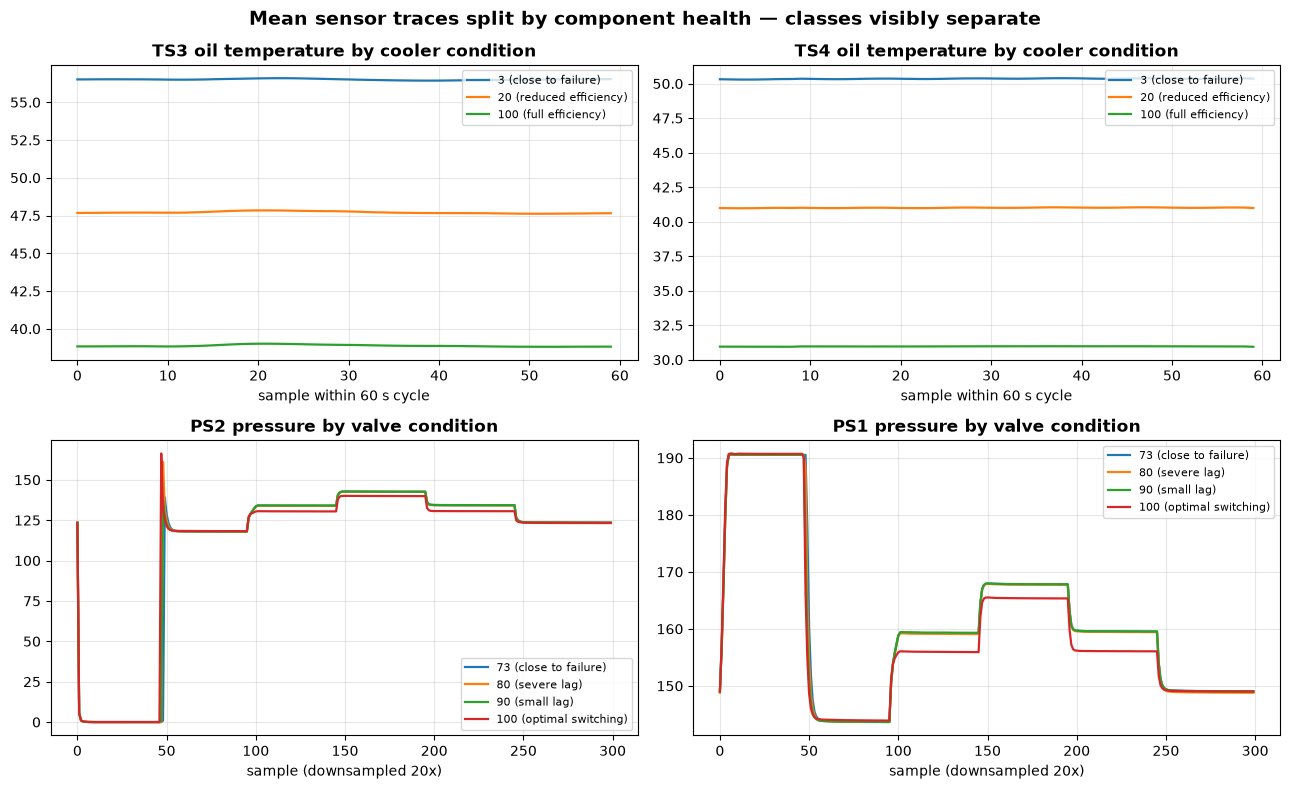

In [7]:
def mean_trace(sensor, target, ax, title):
    mat = load_sensor(sensor)
    for val in sorted(profile[target].unique()):
        tr = mat[profile[target].values == val]
        m = tr.mean(axis=0)
        label = f"{val} ({TARGET_LABELS[target][val]})"
        ax.plot(m, label=label, linewidth=1.6)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("sample within 60 s cycle")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
# temperature sensors vs cooler state (downsampled view: every 1 s already)
mean_trace("TS3", "cooler", axes[0, 0], "TS3 oil temperature by cooler condition")
mean_trace("TS4", "cooler", axes[0, 1], "TS4 oil temperature by cooler condition")
# pressure sensors vs valve state (plot every 20th sample for speed)
for ax, sensor, title in [(axes[1, 0], "PS2", "PS2 pressure by valve condition"),
                          (axes[1, 1], "PS1", "PS1 pressure by valve condition")]:
    mat = load_sensor(sensor)[:, ::20]
    for val in sorted(profile["valve"].unique()):
        tr = mat[profile["valve"].values == val]
        ax.plot(tr.mean(axis=0), label=f"{val} ({TARGET_LABELS['valve'][val]})", linewidth=1.6)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("sample (downsampled 20x)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle("Mean sensor traces split by component health — classes visibly separate",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG}/02_signal_separation.png", dpi=120)
plt.show()


## 7. Takeaways → modeling

1. **Class balance is workable.** Cooler is near-balanced; valve/pump/accumulator are imbalanced but every class has ≥360 cycles — stratified splits will handle it.
2. **Physics is visible in the raw signals.** Cooler degradation lifts the whole temperature trace; valve lag reshapes pressure dynamics. This is exactly what a feature-based classifier should exploit.
3. **Dimensionality is the challenge:** ~38k raw values per cycle → we need compact per-cycle features (statistics + spectral descriptors) before any classifier sees the data.

Next: `02_modeling.ipynb` — feature engineering, one classifier per component, honest evaluation with confusion matrices and sensor-level feature importance.
